# CO5085 E2 — Transformer: MSA và Tokenization

Notebook này được xây dựng để chạy thí nghiệm E2 trên Google Colab theo cùng kiểu quy trình như E1: kiểm tra môi trường, cài đặt phụ thuộc, smoke test, train, kiểm tra output và so sánh kết quả thực tế.

## 1. Cài đặt thư viện và kiểm tra môi trường Colab

Tôi bắt đầu bằng việc xác nhận bản PyTorch, trạng thái GPU và môi trường Colab trước khi đi vào các phần huấn luyện thực tế.

In [9]:
!nvidia-smi

import torch

print("PyTorch version:", torch.__version__)
print("GPU is available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device Name:", torch.cuda.get_device_name(0))

Wed Oct 14 16:31:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [10]:
import os

if not os.path.exists("/content/deep-learning-computer-vision-co5085"):
    %cd /content
    !git clone https://github.com/hoctran19-cyber/deep-learning-computer-vision-co5085.git
    %cd /content/deep-learning-computer-vision-co5085/E2

!pwd
!ls -la

/content
Cloning into 'deep-learning-computer-vision-co5085'...
remote: Enumerating objects: 175, done.
remote: Counting objects: 100% (175/175), done.
remote: Compressing objects: 100% (123/123), done.
remote: Total 175 (delta 56), reused 150 (delta 31), pack-reused 0 (from 0)
Receiving objects: 100% (175/175), 1.55 MiB | 4.85 MiB/s, done.
Resolving deltas: 100% (56/56), done.
/content/deep-learning-computer-vision-co5085/E2
/content/deep-learning-computer-vision-co5085/E2
total 48
drwxr-xr-x  7 root root 4096 Oct 14 16:31 .
drwxr-xr-x 13 root root 4096 Oct 14 16:31 ..
drwxr-xr-x  2 root root 4096 Oct 14 16:31 configs
-rw-r--r--  1 root root  218 Oct 14 16:31 .gitignore
-rw-r--r--  1 root root 2642 Oct 14 16:31 index.html
drwxr-xr-x  2 root root 4096 Oct 14 16:31 notebooks
drwxr-xr-x  6 root root 4096 Oct 14 16:31 outputs
-rw-r--r--  1 root root 7135 Oct 14 16:31 README.md
-rw-r--r--  1 root root   56 Oct 14 16:31 requirements.txt
drwxr-xr-x  2 root root 4096 Oct 14 16:31 src
drwxr-xr

In [11]:
!cat configs/default.yaml

!find . -maxdepth 3 -type f | sort

# E2 default experiment configuration. Dataset follows E1: Fashion-MNIST.
seed: 42

dataset:
  name: fashion_mnist
  data_dir: data
  num_workers: 2
  download: true

experiment:
  validation_split: 0.1

training:
  batch_size: 128
  epochs: 5
  learning_rate: 0.001

optimizer:
  name: adamw
  weight_decay: 0.0001

model:
  tokenizer: patch          # patch, row, or cnn_stem
  attention_type: custom    # custom or torch
  embedding_dim: 64
  num_heads: 4
  num_blocks: 2
  patch_size: 7
  stem_channels: 32
  dropout: 0.1
  mlp_ratio: 2.0

output:
  metrics_dir: outputs/metrics
  figures_dir: outputs/figures
  checkpoints_dir: outputs/checkpoints
  configs_dir: outputs/configs
  # Optional in Colab: set to a Google Drive path after mounting Drive.
  copy_to_dir: null
./configs/default.yaml
./.gitignore
./index.html
./notebooks/e2_experiments.ipynb
./outputs/checkpoints/.gitkeep
./outputs/configs/.gitkeep
./outputs/figures/.gitkeep
./outputs/.gitkeep
./outputs/metrics/.gitkeep
./README.md

## 2. Cài đặt phụ thuộc và import module của dự án

Sau khi xác nhận môi trường, tôi cài đặt các gói cần thiết và import các module chính của E2 để chuẩn bị cho các kiểm tra tiếp theo.

In [12]:
!pip install -r requirements.txt

In [13]:
import os
import sys
from pathlib import Path

repo_path = "/content/deep-learning-computer-vision-co5085/E2"
if os.path.exists(repo_path) and repo_path not in sys.path:
    sys.path.insert(0, repo_path)

from src.utils import get_device, load_config, set_seed
from src.data import load_datasets, create_dataloaders
from src.model import build_model
from src.tokenizers import PatchTokenizer, RowTokenizer, CNNStemTokenizer
from src.attention import CustomMultiHeadSelfAttention, TorchMultiHeadSelfAttention

print("Imports OK!")

Imports OK!


## 3. Tải dataset và kiểm tra batch đầu vào

Trước khi huấn luyện, tôi xác nhận dữ liệu được tải đúng và tensor có shape phù hợp với mô hình Transformer.

In [14]:
config = load_config("configs/default.yaml")
set_seed(config["seed"])
bundle = load_datasets(config, Path.cwd())
loaders = create_dataloaders(bundle, config)
print(bundle.input_shape, bundle.num_classes, bundle.class_names)
images, labels = next(iter(loaders["train"]))
print("Batch:", images.shape, labels.shape)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.40MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.2MB/s]

(1, 28, 28) 10 ['t-shirt/top', 'trouser', 'pullover', 'dress', 'coat', 'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']


Batch: torch.Size([128, 1, 28, 28]) torch.Size([128])


## 4. Smoke test tokenizer

Mỗi tokenizer tạo token theo cách khác nhau; tôi kiểm tra số lượng token và shape đầu ra để đảm bảo tương thích với mô hình.

In [15]:
embedding_dim = config["model"]["embedding_dim"]
tokenizers = {
    "patch": PatchTokenizer(bundle.input_shape, config["model"]["patch_size"], embedding_dim),
    "row": RowTokenizer(bundle.input_shape, embedding_dim),
    "cnn_stem": CNNStemTokenizer(bundle.input_shape, embedding_dim),
}
for name, tokenizer in tokenizers.items():
    tokens = tokenizer(images[:4])
    print(name, "num_tokens =", tokenizer.num_tokens, "shape =", tuple(tokens.shape))

patch num_tokens = 16 shape = (4, 16, 64)
row num_tokens = 28 shape = (4, 28, 64)
cnn_stem num_tokens = 49 shape = (4, 49, 64)


## 5. Smoke test Multi-Head Self-Attention

Tôi kiểm tra cả phiên bản custom MSA và PyTorch MSA để đảm bảo gradient và output shape đều ổn định.

In [16]:
x = torch.randn(2, 8, embedding_dim, requires_grad=True)
for name, module in {
    "custom": CustomMultiHeadSelfAttention(embedding_dim, config["model"]["num_heads"]),
    "torch": TorchMultiHeadSelfAttention(embedding_dim, config["model"]["num_heads"]),
}.items():
    y = module(x)
    y.mean().backward()
    print(name, tuple(y.shape), "grad ok:", x.grad is not None)

custom (2, 8, 64) grad ok: True
torch (2, 8, 64) grad ok: True


## 6. Smoke test mô hình hoàn chỉnh

Trước khi chạy các thí nghiệm dài, tôi thực hiện một bước forward/backward ngắn để xác nhận mô hình hoạt động đúng.

In [17]:
model = build_model(config, bundle.input_shape, bundle.num_classes).to(get_device())
batch = images[:8].to(get_device())
targets = labels[:8].to(get_device())
logits = model(batch)
loss = torch.nn.CrossEntropyLoss()(logits, targets)
loss.backward()
print("logits:", logits.shape, "loss:", float(loss.detach().cpu()))

logits: torch.Size([8, 10]) loss: 2.2251524925231934


## 7. Kiểm tra CLI training

Tôi xác nhận script huấn luyện có thể chạy theo CLI trước khi thực hiện các thí nghiệm lớn hơn.

In [18]:
!python -m src.train --help

usage: train.py [-h] [--config CONFIG] [--experiment-name EXPERIMENT_NAME]
                [--attention {custom,torch}]
                [--tokenizer {patch,row,cnn_stem}] [--epochs EPOCHS]
                [--batch-size BATCH_SIZE] [--lr LR] [--resume RESUME]

Train one E2 Transformer image classifier.

options:
  -h, --help            show this help message and exit
  --config CONFIG
  --experiment-name EXPERIMENT_NAME
  --attention {custom,torch}
  --tokenizer {patch,row,cnn_stem}
  --epochs EPOCHS
  --batch-size BATCH_SIZE
  --lr LR
  --resume RESUME


In [25]:
!python -m src.train --config configs/default.yaml --experiment-name smoke_custom_patch --attention custom --tokenizer patch --epochs 5 --batch-size 64

epoch=1/5 train_loss=0.7418 val_loss=0.4882 train_acc=0.7375 val_acc=0.8292
epoch=2/5 train_loss=0.5056 val_loss=0.4443 train_acc=0.8179 val_acc=0.8372
epoch=3/5 train_loss=0.4576 val_loss=0.4005 train_acc=0.8339 val_acc=0.8570
epoch=4/5 train_loss=0.4272 val_loss=0.4003 train_acc=0.8449 val_acc=0.8548
epoch=5/5 train_loss=0.4121 val_loss=0.3737 train_acc=0.8487 val_acc=0.8627
Completed smoke_custom_patch on cuda; test accuracy: 0.8571


## 8. Huấn luyện thí nghiệm A: so sánh MSA

Bộ thí nghiệm A giữ nguyên tokenizer patch, chỉ thay đổi custom MSA và PyTorch MSA để so sánh hiệu suất và độ ổn định.

In [20]:
!python -m src.train --config configs/default.yaml --experiment-name msa_custom_patch --attention custom --tokenizer patch
!python -m src.train --config configs/default.yaml --experiment-name msa_torch_patch --attention torch --tokenizer patch

epoch=1/5 train_loss=0.8234 val_loss=0.5055 train_acc=0.7104 val_acc=0.8222
epoch=2/5 train_loss=0.5211 val_loss=0.4417 train_acc=0.8131 val_acc=0.8415
epoch=3/5 train_loss=0.4661 val_loss=0.4292 train_acc=0.8332 val_acc=0.8477
epoch=4/5 train_loss=0.4368 val_loss=0.4112 train_acc=0.8407 val_acc=0.8527
epoch=5/5 train_loss=0.4150 val_loss=0.3773 train_acc=0.8486 val_acc=0.8582
Completed msa_custom_patch on cuda; test accuracy: 0.8547
epoch=1/5 train_loss=0.8166 val_loss=0.5297 train_acc=0.7125 val_acc=0.8145
epoch=2/5 train_loss=0.5294 val_loss=0.4611 train_acc=0.8087 val_acc=0.8320
epoch=3/5 train_loss=0.4783 val_loss=0.4309 train_acc=0.8267 val_acc=0.8458
epoch=4/5 train_loss=0.4390 val_loss=0.4009 train_acc=0.8399 val_acc=0.8508
epoch=5/5 train_loss=0.4169 val_loss=0.3742 train_acc=0.8473 val_acc=0.8592
Completed msa_torch_patch on cuda; test accuracy: 0.8567


## 9. Huấn luyện thí nghiệm B: so sánh tokenizer

Bộ thí nghiệm B giữ nguyên custom MSA, so sánh hiệu quả của patch, row và cnn_stem tokenizer.

In [21]:
!python -m src.train --config configs/default.yaml --experiment-name tok_patch_custom --attention custom --tokenizer patch
!python -m src.train --config configs/default.yaml --experiment-name tok_row_custom --attention custom --tokenizer row
!python -m src.train --config configs/default.yaml --experiment-name tok_cnn_stem_custom --attention custom --tokenizer cnn_stem

epoch=1/5 train_loss=0.8234 val_loss=0.5055 train_acc=0.7104 val_acc=0.8222
epoch=2/5 train_loss=0.5211 val_loss=0.4417 train_acc=0.8131 val_acc=0.8415
epoch=3/5 train_loss=0.4661 val_loss=0.4292 train_acc=0.8332 val_acc=0.8477
epoch=4/5 train_loss=0.4368 val_loss=0.4112 train_acc=0.8407 val_acc=0.8527
epoch=5/5 train_loss=0.4150 val_loss=0.3773 train_acc=0.8486 val_acc=0.8582
Completed tok_patch_custom on cuda; test accuracy: 0.8547
epoch=1/5 train_loss=0.6689 val_loss=0.5217 train_acc=0.7603 val_acc=0.8112
epoch=2/5 train_loss=0.4549 val_loss=0.3948 train_acc=0.8347 val_acc=0.8600
epoch=3/5 train_loss=0.4060 val_loss=0.3892 train_acc=0.8512 val_acc=0.8630
epoch=4/5 train_loss=0.3790 val_loss=0.3658 train_acc=0.8610 val_acc=0.8698
epoch=5/5 train_loss=0.3578 val_loss=0.3503 train_acc=0.8695 val_acc=0.8725
Completed tok_row_custom on cuda; test accuracy: 0.8665
epoch=1/5 train_loss=0.7719 val_loss=0.5028 train_acc=0.7200 val_acc=0.8240
epoch=2/5 train_loss=0.4702 val_loss=0.4573 train_

## 10. Kiểm tra kết quả đầu ra

Sau khi chạy xong các thí nghiệm, tôi kiểm tra các file metrics, CSV so sánh và hình ảnh learning curves / confusion matrix được sinh ra.

In [27]:
!find outputs -maxdepth 3 -type f | sort

import pandas as pd
from pathlib import Path

comparison_path = Path("outputs/metrics/comparison.csv")
if comparison_path.exists():
    display(pd.read_csv(comparison_path))
else:
    print("Chưa có comparison.csv vì thí nghiệm chưa chạy xong.")

outputs/checkpoints/.gitkeep
outputs/checkpoints/msa_custom_patch.pt
outputs/checkpoints/msa_torch_patch.pt
outputs/checkpoints/smoke_custom_patch.pt
outputs/checkpoints/tok_cnn_stem_custom.pt
outputs/checkpoints/tok_patch_custom.pt
outputs/checkpoints/tok_row_custom.pt
outputs/configs/.gitkeep
outputs/configs/msa_custom_patch.json
outputs/configs/msa_torch_patch.json
outputs/configs/smoke_custom_patch.json
outputs/configs/tok_cnn_stem_custom.json
outputs/configs/tok_patch_custom.json
outputs/configs/tok_row_custom.json
outputs/figures/.gitkeep
outputs/figures/msa_custom_patch_confusion_matrix.png
outputs/figures/msa_custom_patch_learning_curves.png
outputs/figures/msa_torch_patch_confusion_matrix.png
outputs/figures/msa_torch_patch_learning_curves.png
outputs/figures/smoke_custom_patch_confusion_matrix.png
outputs/figures/smoke_custom_patch_learning_curves.png
outputs/figures/tok_cnn_stem_custom_confusion_matrix.png
outputs/figures/tok_cnn_stem_custom_learning_curves.png
outputs/figur

,experiment_name,attention_type,tokenizer,test_accuracy,best_validation_accuracy,num_parameters,training_time,inference_time
0,smoke_custom_patch,custom,patch,0.8571,0.862667,72074,82.550669,2.255791
1,msa_custom_patch,custom,patch,0.8547,0.858167,72074,65.224107,1.922715
2,msa_torch_patch,torch,patch,0.8567,0.859167,72074,63.675532,1.903387
3,tok_patch_custom,custom,patch,0.8547,0.858167,72074,64.280737,1.912128
4,tok_row_custom,custom,row,0.8665,0.872500,71498,65.373277,1.922320
5,tok_cnn_stem_custom,custom,cnn_stem,0.8607,0.869000,89802,66.887445,1.978462


msa_custom_patch_confusion_matrix.png


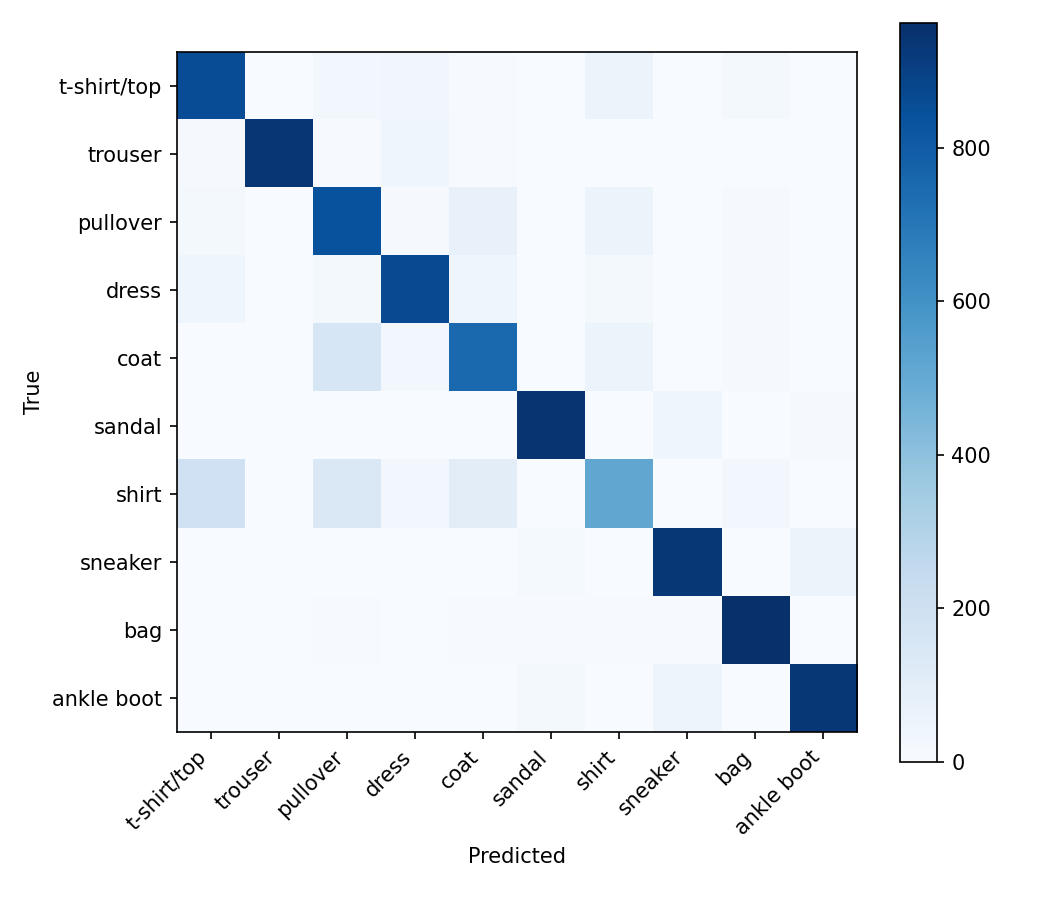

msa_custom_patch_learning_curves.png


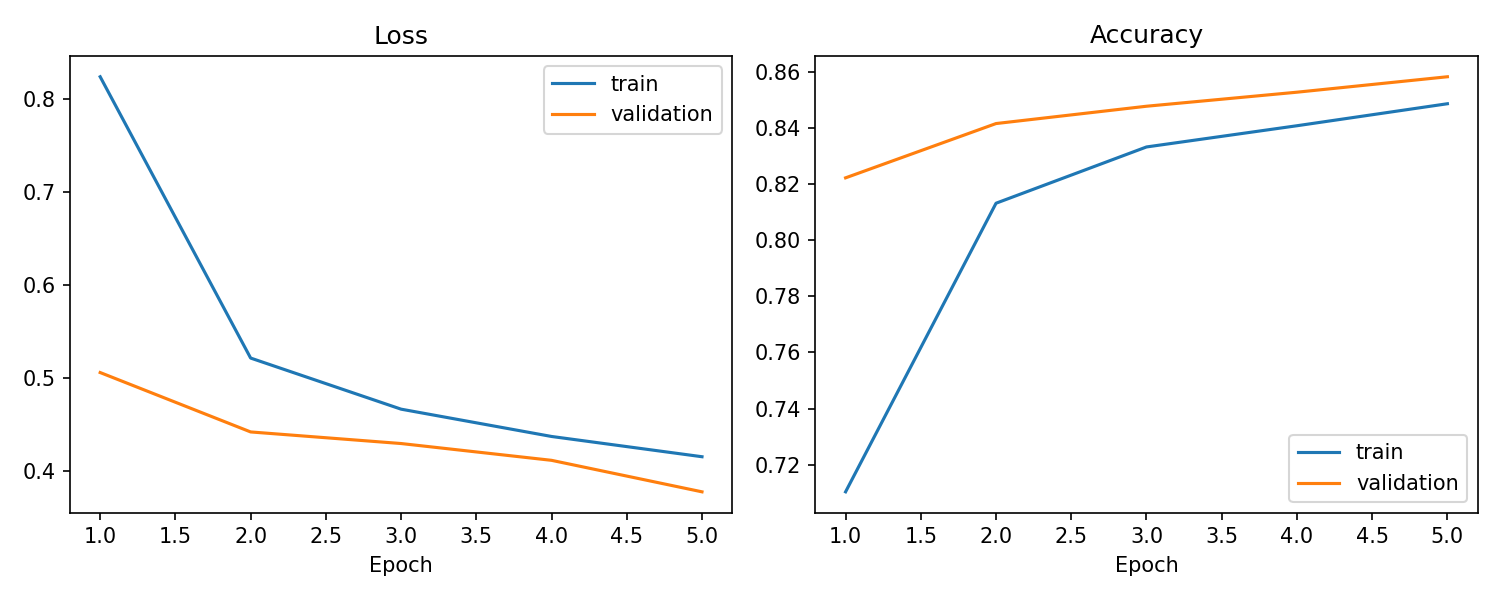

msa_torch_patch_confusion_matrix.png


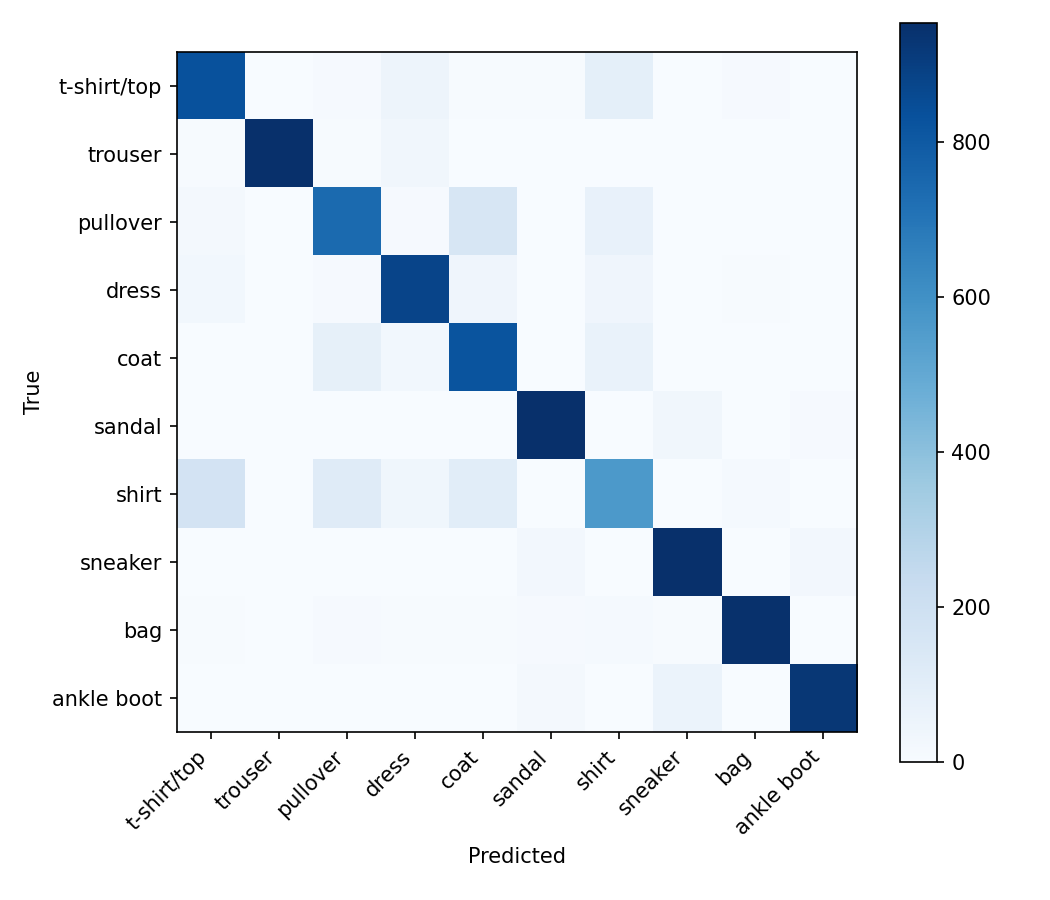

msa_torch_patch_learning_curves.png


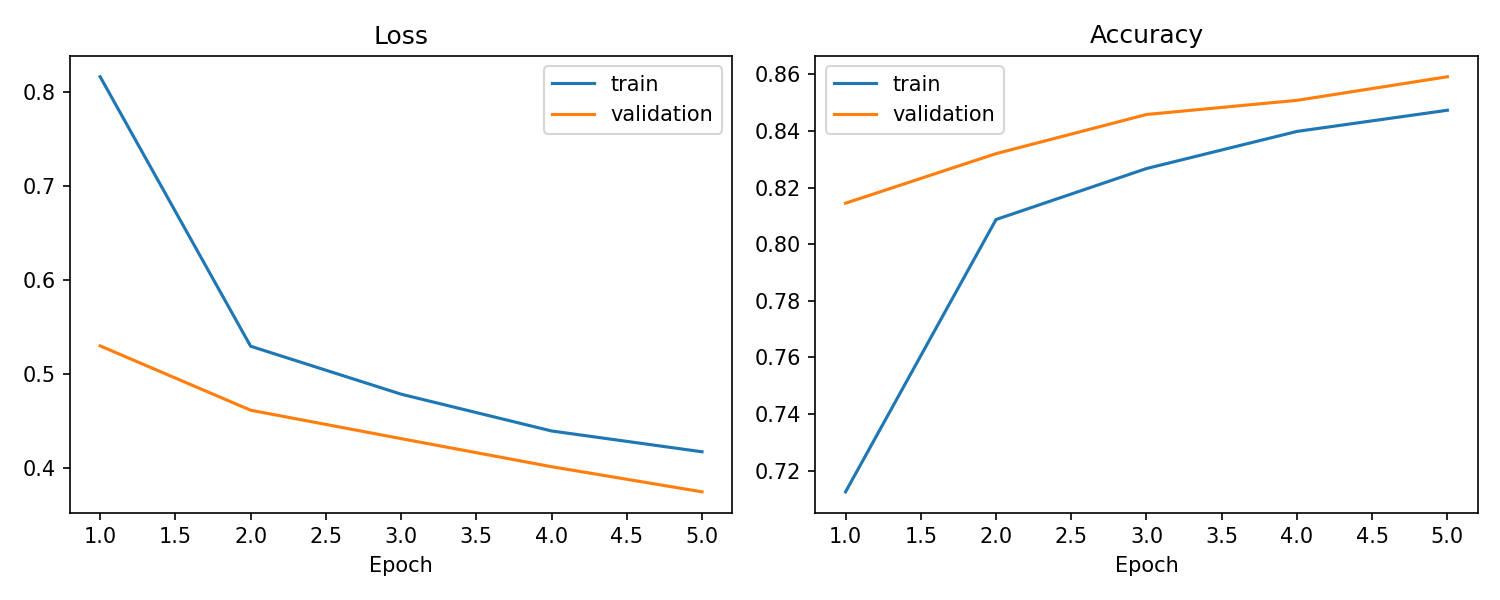

smoke_custom_patch_confusion_matrix.png


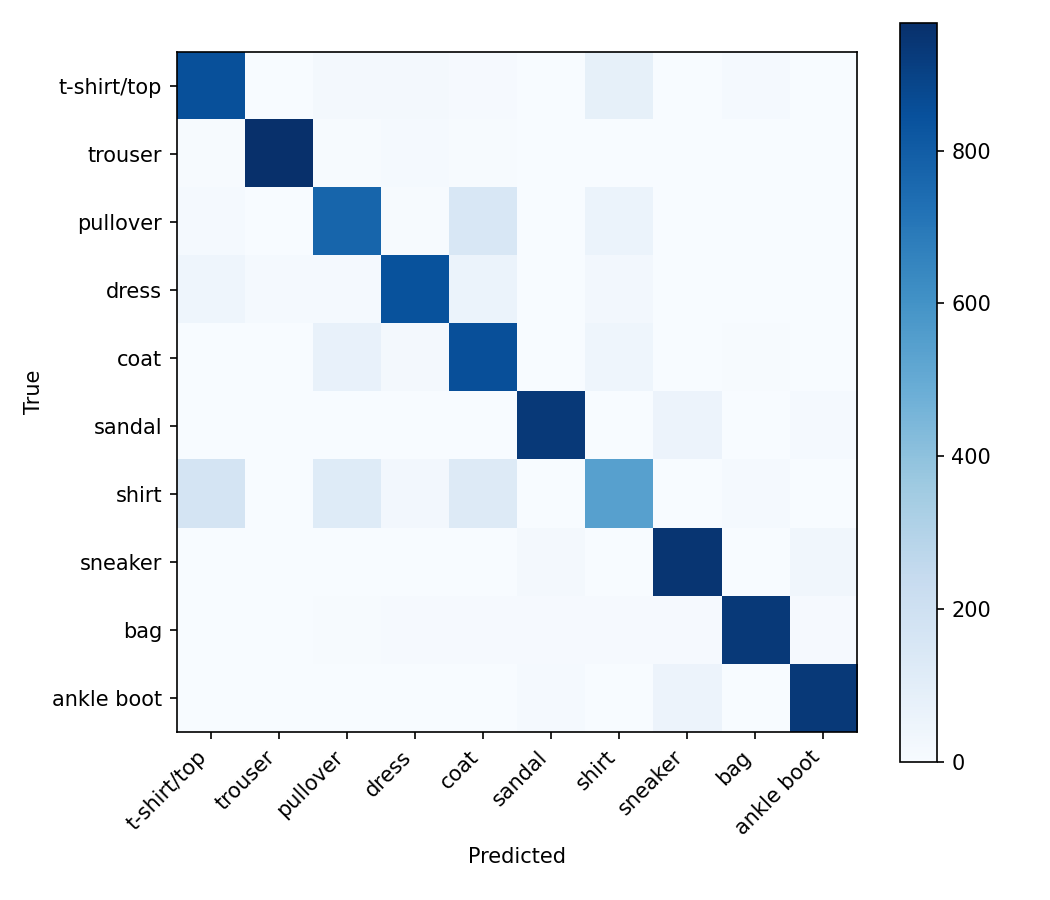

smoke_custom_patch_learning_curves.png


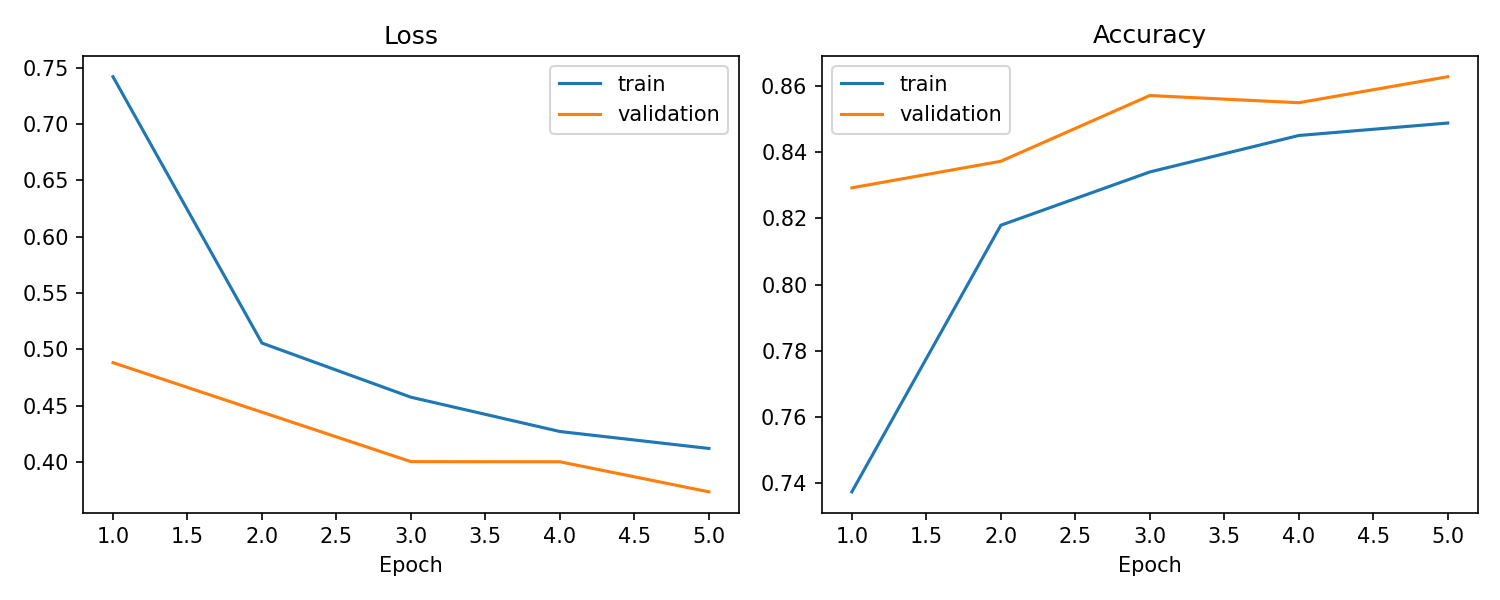

In [26]:
from IPython.display import Image, display
from pathlib import Path

figures = sorted(Path("outputs/figures").glob("*.png"))
for figure in figures[:6]:
    print(figure.name)
    display(Image(filename=str(figure)))

## 11. Đọc chi tiết các file metrics

Tôi đọc từng file JSON của các thí nghiệm để xem độ chính xác, best validation accuracy, số tham số và lịch sử học tập.

In [24]:
import json
from pathlib import Path

for name in ["msa_custom_patch", "msa_torch_patch", "tok_patch_custom", "tok_row_custom", "tok_cnn_stem_custom"]:
    p = Path(f"outputs/metrics/{name}.json")
    if p.exists():
        with p.open("r", encoding="utf-8") as f:
            data = json.load(f)
        print(f"\n=== {name} ===")
        print("test_accuracy:", data.get("test", {}).get("accuracy"))
        print("best_validation_accuracy:", data.get("best_validation_accuracy"))
        print("num_parameters:", data.get("num_parameters"))
        print("history_keys:", list(data.get("history", {}).keys()))
    else:
        print(f"\n=== {name} ===")
        print("Chưa có file metrics cho experiment này.")


=== msa_custom_patch ===
test_accuracy: 0.8547
best_validation_accuracy: 0.8581666666666666
num_parameters: 72074
history_keys: ['train_loss', 'validation_loss', 'train_accuracy', 'validation_accuracy']

=== msa_torch_patch ===
test_accuracy: 0.8567
best_validation_accuracy: 0.8591666666666666
num_parameters: 72074
history_keys: ['train_loss', 'validation_loss', 'train_accuracy', 'validation_accuracy']

=== tok_patch_custom ===
test_accuracy: 0.8547
best_validation_accuracy: 0.8581666666666666
num_parameters: 72074
history_keys: ['train_loss', 'validation_loss', 'train_accuracy', 'validation_accuracy']

=== tok_row_custom ===
test_accuracy: 0.8665
best_validation_accuracy: 0.8725
num_parameters: 71498
history_keys: ['train_loss', 'validation_loss', 'train_accuracy', 'validation_accuracy']

=== tok_cnn_stem_custom ===
test_accuracy: 0.8607
best_validation_accuracy: 0.869
num_parameters: 89802
history_keys: ['train_loss', 'validation_loss', 'train_accuracy', 'validation_accuracy']


## 12. Kết luận và nhận xét

Sau khi chạy xong các thí nghiệm, tôi sẽ so sánh hiệu suất của các cấu hình MSA và tokenizer để rút ra nhận xét về mô hình nào thích hợp hơn cho bài toán phân loại ảnh Fashion-MNIST. Các nhận xét định lượng chỉ được viết sau khi có đủ metrics thật từ quá trình chạy.